### networkx 3: Kürzeste Wege und minimale Spannbäume - Übungen

In **gewichteten** Graphen hat jede Kante eine Länge, Dauer oder Kosten. Gesucht ist dann nicht der Weg mit den wenigsten Kanten, sondern der mit dem
**kleinsten Gesamtgewicht**: der kürzeste Weg im Straßennetz, die schnellste Verbindung, die billigste Leitung.

Die Reihe hat vier Notebooks:

1. Grundlagen: Graphen erstellen, untersuchen und zeichnen
2. Suchen: Wege, Zusammenhang, Breiten- und Tiefensuche, Abhängigkeiten
3. **Gewichtete Graphen**: kürzeste Wege (Dijkstra, Bellman-Ford), minimale Spannbäume (dieses Notebook)
4. Probleme: Euler-Wege, Färbungen, Dominating Sets, Rundreisen, soziale Netze

Die Abschnitte über Bellman-Ford und minimale Spannbäume sind für das **Leistungsfach** gedacht.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Manche Beispiele enden absichtlich mit einer Fehlermeldung. Danach folgen viele kleine Übungen.
Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Kürzeste Wege mit Dijkstra

#### Der Algorithmus von Dijkstra

Der **Algorithmus von Dijkstra** findet in Graphen mit **nicht negativen** Gewichten den Weg mit dem kleinsten Gesamtgewicht. In networkx:

| Aufruf | Ergebnis |
|---|---|
| `nx.dijkstra_path(G, u, v)` | der kürzeste Weg als Liste von Knoten |
| `nx.dijkstra_path_length(G, u, v)` | seine Länge (Summe der Gewichte) |
| `nx.single_source_dijkstra_path_length(G, u)` | Dictionary: Entfernung von u zu allen Knoten |
| `nx.path_weight(G, weg, weight='weight')` | Gesamtgewicht eines beliebigen Weges |

Die Gewichte stehen im Kantenattribut `weight`. `nx.shortest_path(G, u, v)` **ohne** `weight=` zählt nur Kanten (wie die Breitensuche im vorigen Notebook);
`nx.shortest_path(G, u, v, weight='weight')` benutzt Dijkstra.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2), ('c', 'b', 1), ('b', 'd', 4), ('c', 'd', 6)])
print(nx.dijkstra_path(G, 'a', 'd'), nx.dijkstra_path_length(G, 'a', 'd'))
print(nx.shortest_path(G, 'a', 'd'))
print(nx.path_weight(G, ['a', 'b', 'd'], weight='weight'))
print(nx.single_source_dijkstra_path_length(G, 'a'))

#### Aufgabe 1.1

Gib den kürzesten Weg von Mannheim nach Konstanz und seine Länge in km aus.

**Erwartete Ausgabe:**
```
['Mannheim', 'Heilbronn', 'Stuttgart', 'Tübingen', 'Konstanz']
335
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
print(nx.dijkstra_path(BW, 'Mannheim', 'Konstanz'))
print(nx.dijkstra_path_length(BW, 'Mannheim', 'Konstanz'))
```

</details>

#### Aufgabe 1.2

Gib den Weg mit den **wenigsten Straßen** von Mannheim nach Konstanz aus (`shortest_path` ohne Gewicht) und seine Länge in km (`path_weight`). Vergleiche mit der Aufgabe davor.

**Erwartete Ausgabe:**
```
['Mannheim', 'Karlsruhe', 'Stuttgart', 'Ulm', 'Konstanz']
390
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
weg = nx.shortest_path(BW, 'Mannheim', 'Konstanz')
print(weg)
print(nx.path_weight(BW, weg, weight='weight'))
```

</details>

#### Aufgabe 1.3

Gib die Entfernungen von Stuttgart zu allen Städten aus, nach Entfernung sortiert, in der Form `Tübingen: 45 km`.

**Erwartete Ausgabe:**
```
Stuttgart: 0 km
Tübingen: 45 km
Pforzheim: 50 km
Heilbronn: 55 km
Karlsruhe: 80 km
Ulm: 95 km
Baden-Baden: 120 km
Mannheim: 140 km
Konstanz: 195 km
Freiburg: 225 km
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
d = nx.single_source_dijkstra_path_length(BW, 'Stuttgart')
for stadt in sorted(d, key=lambda s: d[s]):
    print(f'{stadt}: {d[stadt]} km')
```

</details>

#### Aufgabe 1.4

Ein Lieferwagen fährt von Karlsruhe nach Ulm und muss unterwegs in Tübingen ausliefern. Gib den kürzesten Gesamtweg (beide Teilwege aneinandergehängt, Tübingen nur einmal) und seine Länge aus.

**Erwartete Ausgabe:**
```
['Karlsruhe', 'Stuttgart', 'Tübingen', 'Ulm']
235
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
weg1 = nx.dijkstra_path(BW, 'Karlsruhe', 'Tübingen')
weg2 = nx.dijkstra_path(BW, 'Tübingen', 'Ulm')
print(weg1 + weg2[1:])
print(nx.dijkstra_path_length(BW, 'Karlsruhe', 'Tübingen') + nx.dijkstra_path_length(BW, 'Tübingen', 'Ulm'))
```

</details>

#### Aufgabe 1.5

Welche Städte liegen mit dem Auto höchstens 100 km von Karlsruhe entfernt (außer Karlsruhe selbst)? Gib sie sortiert aus.

**Erwartete Ausgabe:**
```
['Baden-Baden', 'Mannheim', 'Pforzheim', 'Stuttgart']
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
d = nx.single_source_dijkstra_path_length(BW, 'Karlsruhe')
nah = []
for stadt, km in d.items():
    if 0 < km <= 100:
        nah.append(stadt)
print(sorted(nah))
```

</details>

#### Aufgabe 1.6

Die Straße Stuttgart–Tübingen wird gesperrt (`remove_edge`). Gib den neuen kürzesten Weg von Stuttgart nach Konstanz und den Umweg in km (neue Länge minus alte Länge) aus.

**Erwartete Ausgabe:**
```
['Stuttgart', 'Ulm', 'Konstanz']
45
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
alt = nx.dijkstra_path_length(BW, 'Stuttgart', 'Konstanz')
BW.remove_edge('Stuttgart', 'Tübingen')
print(nx.dijkstra_path(BW, 'Stuttgart', 'Konstanz'))
print(nx.dijkstra_path_length(BW, 'Stuttgart', 'Konstanz') - alt)
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 1), ('b', 'c', 1), ('a', 'c', 5)])
print(nx.shortest_path(G, 'a', 'c'))
print(nx.dijkstra_path(G, 'a', 'c'), nx.dijkstra_path_length(G, 'a', 'c'))
```

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 1), ('b', 'c', 1), ('a', 'c', 5)])
print(nx.shortest_path(G, 'a', 'c'))
print(nx.dijkstra_path(G, 'a', 'c'), nx.dijkstra_path_length(G, 'a', 'c'))

## 2. Verschiedene Gewichte und gerichtete Netze

#### Mehrere Attribute

Eine Kante kann mehrere Attribute haben, z. B. Entfernung **und** Fahrzeit. Mit `weight='minuten'` sagt man den Funktionen, welches Attribut sie benutzen sollen.
Der kürzeste Weg ist dann nicht unbedingt der schnellste.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_edge('A', 'B', km=10, minuten=15)
G.add_edge('B', 'C', km=10, minuten=15)
G.add_edge('A', 'C', km=25, minuten=18)
print(nx.dijkstra_path(G, 'A', 'C', weight='km'), nx.dijkstra_path_length(G, 'A', 'C', weight='km'))
print(nx.dijkstra_path(G, 'A', 'C', weight='minuten'), nx.dijkstra_path_length(G, 'A', 'C', weight='minuten'))

#### Aufgabe 2.1

Gib für eine Radtour von Start nach Ziel den kürzesten Weg (nach `km`) und den mit den wenigsten Höhenmetern (nach `hoehenmeter`) aus, jeweils mit km und Höhenmetern.

**Erwartete Ausgabe:**
```
['Start', 'Dorf', 'Pass', 'Ziel'] 21 470
['Start', 'Tal', 'See', 'Ziel'] 31 180
```

In [ ]:
import networkx as nx

R = nx.Graph()
for u, v, km, hm in [('Start', 'Dorf', 8, 50), ('Dorf', 'Pass', 6, 400), ('Pass', 'Ziel', 7, 20), ('Start', 'Tal', 12, 0),
                     ('Tal', 'See', 10, 30), ('See', 'Ziel', 9, 150), ('Dorf', 'See', 7, 80)]:
    R.add_edge(u, v, km=km, hoehenmeter=hm)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

R = nx.Graph()
for u, v, km, hm in [('Start', 'Dorf', 8, 50), ('Dorf', 'Pass', 6, 400), ('Pass', 'Ziel', 7, 20), ('Start', 'Tal', 12, 0),
                     ('Tal', 'See', 10, 30), ('See', 'Ziel', 9, 150), ('Dorf', 'See', 7, 80)]:
    R.add_edge(u, v, km=km, hoehenmeter=hm)
for gewicht in ['km', 'hoehenmeter']:
    weg = nx.dijkstra_path(R, 'Start', 'Ziel', weight=gewicht)
    print(weg, nx.path_weight(R, weg, weight='km'), nx.path_weight(R, weg, weight='hoehenmeter'))
```

</details>

#### Aufgabe 2.2

Eine Radfahrerin bewertet eine Strecke mit „Anstrengung“ = km + Höhenmeter / 50. Speichere dieses Attribut bei jeder Kante (Schleife über `R.edges(data=True)`, das dritte Element
ist das Dictionary der Attribute) und gib den Weg mit der geringsten Anstrengung und seine Anstrengung aus.

**Erwartete Ausgabe:**
```
['Start', 'Dorf', 'See', 'Ziel'] 29.6
```

In [ ]:
import networkx as nx

R = nx.Graph()
for u, v, km, hm in [('Start', 'Dorf', 8, 50), ('Dorf', 'Pass', 6, 400), ('Pass', 'Ziel', 7, 20), ('Start', 'Tal', 12, 0),
                     ('Tal', 'See', 10, 30), ('See', 'Ziel', 9, 150), ('Dorf', 'See', 7, 80)]:
    R.add_edge(u, v, km=km, hoehenmeter=hm)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

R = nx.Graph()
for u, v, km, hm in [('Start', 'Dorf', 8, 50), ('Dorf', 'Pass', 6, 400), ('Pass', 'Ziel', 7, 20), ('Start', 'Tal', 12, 0),
                     ('Tal', 'See', 10, 30), ('See', 'Ziel', 9, 150), ('Dorf', 'See', 7, 80)]:
    R.add_edge(u, v, km=km, hoehenmeter=hm)
for u, v, attr in R.edges(data=True):
    attr['anstrengung'] = attr['km'] + attr['hoehenmeter'] / 50
weg = nx.dijkstra_path(R, 'Start', 'Ziel', weight='anstrengung')
print(weg, nx.dijkstra_path_length(R, 'Start', 'Ziel', weight='anstrengung'))
```

</details>

#### Aufgabe 2.3

In einer Stadt mit Einbahnstraßen (`E`, gerichtet, Gewicht in Minuten) unterscheiden sich Hin- und Rückweg. Gib den schnellsten Weg vom Bahnhof zum Stadion und zurück aus, jeweils mit Dauer.

**Erwartete Ausgabe:**
```
['Bahnhof', 'Markt', 'Stadion'] 10
['Stadion', 'Park', 'Bahnhof'] 8
```

In [ ]:
import networkx as nx

E = nx.DiGraph()
E.add_weighted_edges_from([('Bahnhof', 'Markt', 4), ('Markt', 'Stadion', 6), ('Stadion', 'Park', 3), ('Park', 'Bahnhof', 5),
                          ('Markt', 'Park', 2), ('Stadion', 'Markt', 9), ('Bahnhof', 'Park', 8)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

E = nx.DiGraph()
E.add_weighted_edges_from([('Bahnhof', 'Markt', 4), ('Markt', 'Stadion', 6), ('Stadion', 'Park', 3), ('Park', 'Bahnhof', 5),
                          ('Markt', 'Park', 2), ('Stadion', 'Markt', 9), ('Bahnhof', 'Park', 8)])
for u, v in [('Bahnhof', 'Stadion'), ('Stadion', 'Bahnhof')]:
    print(nx.dijkstra_path(E, u, v), nx.dijkstra_path_length(E, u, v))
```

</details>

#### Aufgabe 2.4

Im Busnetz `B` (Gewicht: Fahrzeit in Minuten) kostet jedes **Umsteigen** 5 Minuten. Die Linie steht im Attribut `linie`. Berechne für die beiden möglichen Wege in `wege` die Fahrzeit plus
5 Minuten für jeden Linienwechsel und gib beide Gesamtzeiten aus.

**Erwartete Ausgabe:**
```
['A', 'B', 'C', 'D'] 13
['A', 'B', 'E', 'D'] 20
```

In [ ]:
import networkx as nx

B = nx.Graph()
for u, v, m, l in [('A', 'B', 4, '1'), ('B', 'C', 5, '1'), ('C', 'D', 4, '1'), ('B', 'E', 3, '2'), ('E', 'D', 3, '3')]:
    B.add_edge(u, v, weight=m, linie=l)
wege = [['A', 'B', 'C', 'D'], ['A', 'B', 'E', 'D']]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

B = nx.Graph()
for u, v, m, l in [('A', 'B', 4, '1'), ('B', 'C', 5, '1'), ('C', 'D', 4, '1'), ('B', 'E', 3, '2'), ('E', 'D', 3, '3')]:
    B.add_edge(u, v, weight=m, linie=l)
wege = [['A', 'B', 'C', 'D'], ['A', 'B', 'E', 'D']]
for weg in wege:
    zeit = nx.path_weight(B, weg, weight='weight')
    for i in range(len(weg) - 2):
        if B[weg[i]][weg[i + 1]]['linie'] != B[weg[i + 1]][weg[i + 2]]['linie']:
            zeit += 5
    print(weg, zeit)
```

</details>

#### Aufgabe 2.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([(1, 2, 3), (2, 3, 3), (3, 1, 1), (1, 3, 9)])
print(nx.dijkstra_path_length(G, 1, 3), nx.dijkstra_path_length(G, 3, 2))
```

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([(1, 2, 3), (2, 3, 3), (3, 1, 1), (1, 3, 9)])
print(nx.dijkstra_path_length(G, 1, 3), nx.dijkstra_path_length(G, 3, 2))

## 3. Entfernungstabellen

#### Alle Paare

`dict(nx.all_pairs_dijkstra_path_length(G))` berechnet die kürzesten Entfernungen **zwischen allen Paaren** von Knoten: ein Dictionary von Dictionaries,
`d[u][v]` ist die Entfernung von u nach v. So entstehen Entfernungstabellen wie im Autoatlas.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 8), ('a', 'c', 2), ('c', 'b', 1), ('b', 'd', 4), ('c', 'd', 6)])
d = dict(nx.all_pairs_dijkstra_path_length(G))
print(d['a']['d'], d['d']['a'])
for u in ['a', 'b', 'c', 'd']:
    print(u, d[u]['a'], d[u]['b'], d[u]['c'], d[u]['d'])

#### Aufgabe 3.1

Gib eine Entfernungstabelle für Stuttgart, Karlsruhe, Freiburg, Konstanz und Ulm aus: eine Kopfzeile mit den Namen (je 10 Zeichen breit, `:>10`) und dann für jede Stadt eine Zeile.

**Erwartete Ausgabe:**
```
           Stuttgart Karlsruhe  Freiburg  Konstanz       Ulm
Stuttgart          0        80       225       195        95
Karlsruhe         80         0       145       275       175
Freiburg         225       145         0       135       280
Konstanz         195       275       135         0       145
Ulm               95       175       280       145         0
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
staedte = ['Stuttgart', 'Karlsruhe', 'Freiburg', 'Konstanz', 'Ulm']
d = dict(nx.all_pairs_dijkstra_path_length(BW))
kopf = ' ' * 10
for s in staedte:
    kopf += f'{s:>10}'
print(kopf)
for u in staedte:
    zeile = f'{u:<10}'
    for v in staedte:
        zeile += f'{d[u][v]:>10}'
    print(zeile)
```

</details>

#### Aufgabe 3.2

Ein Lager soll in der Stadt gebaut werden, von der aus die **weiteste** Fahrt zu einer anderen Stadt möglichst kurz ist. Berechne für jede Stadt die größte Entfernung und gib die beste
Stadt mit diesem Wert aus.

**Erwartete Ausgabe:**
```
Stuttgart 225
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
d = dict(nx.all_pairs_dijkstra_path_length(BW))
weiteste = {}
for u in BW.nodes:
    weiteste[u] = max(d[u].values())
beste = min(weiteste, key=lambda s: weiteste[s])
print(beste, weiteste[beste])
```

</details>

#### Aufgabe 3.3

Ein Vertreter wohnt in einer der Städte und besucht jede Woche alle anderen Städte einzeln (hin und zurück). Von welcher Stadt aus ist die Summe aller Hin- und Rückwege am kleinsten?
Gib die Stadt und die Summe aus.

**Erwartete Ausgabe:**
```
Stuttgart 2010
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
d = dict(nx.all_pairs_dijkstra_path_length(BW))
summen = {}
for u in BW.nodes:
    summen[u] = 2 * sum(d[u].values())
beste = min(summen, key=lambda s: summen[s])
print(beste, summen[beste])
```

</details>

## 4. Negative Gewichte: Bellman-Ford (Leistungsfach)

#### Wenn Gewichte negativ sind

Manchmal sind Gewichte negativ: Ein E-Auto **gewinnt** bergab Energie zurück, eine Buchung kann eine Gutschrift sein.
Dijkstra setzt voraus, dass ein Weg durch weitere Kanten nie kürzer wird. Bei negativen Gewichten stimmt das nicht mehr: networkx liefert dann ein **falsches Ergebnis**
oder bricht mit einem `ValueError` ab (wenn es den Widerspruch bemerkt).

Der **Algorithmus von Bellman-Ford** kommt mit negativen Gewichten zurecht: `nx.bellman_ford_path(G, u, v)` und `nx.bellman_ford_path_length(G, u, v)`.

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('s', 'a', 2), ('s', 'b', 5), ('b', 'a', -4), ('a', 't', 1)])
print(nx.bellman_ford_path(G, 's', 't'), nx.bellman_ford_path_length(G, 's', 't'))
print(nx.dijkstra_path(G, 's', 't'), nx.dijkstra_path_length(G, 's', 't'))
print(nx.single_source_dijkstra_path_length(G, 's'))

#### Negative Kreise

Gibt es einen **Kreis mit negativer Summe**, kann man ihn beliebig oft durchlaufen und jeden Weg beliebig „kurz“ machen. Dann gibt es keinen kürzesten Weg.
`nx.negative_edge_cycle(G)` prüft, ob es einen solchen Kreis gibt; Bellman-Ford wirft dann `NetworkXUnbounded`.

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('a', 'b', 3), ('b', 'c', -2), ('c', 'a', -2), ('c', 'd', 1)])
print(nx.negative_edge_cycle(G))
print(nx.bellman_ford_path(G, 'a', 'd'))

#### Aufgabe 4.1

Ein E-Auto fährt durch bergiges Land (`E`, Gewicht: Energie in kWh, negativ heißt: Energie wird zurückgewonnen). Gib den energiesparendsten Weg vom Tal zum See und den Verbrauch
mit Bellman-Ford aus.

**Erwartete Ausgabe:**
```
['Tal', 'Stadt', 'See']
9
```

In [ ]:
import networkx as nx

E = nx.DiGraph()
E.add_weighted_edges_from([('Tal', 'Hügel', 6), ('Hügel', 'Tal', -2), ('Tal', 'Stadt', 4), ('Hügel', 'Berg', 7), ('Berg', 'Stadt', -3),
                          ('Stadt', 'Berg', 9), ('Hügel', 'Stadt', 3), ('Berg', 'See', -4), ('Stadt', 'See', 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

E = nx.DiGraph()
E.add_weighted_edges_from([('Tal', 'Hügel', 6), ('Hügel', 'Tal', -2), ('Tal', 'Stadt', 4), ('Hügel', 'Berg', 7), ('Berg', 'Stadt', -3),
                          ('Stadt', 'Berg', 9), ('Hügel', 'Stadt', 3), ('Berg', 'See', -4), ('Stadt', 'See', 5)])
print(nx.bellman_ford_path(E, 'Tal', 'See'))
print(nx.bellman_ford_path_length(E, 'Tal', 'See'))
```

</details>

#### Aufgabe 4.2

Prüfe, ob es im Netz `E` einen negativen Kreis gibt. Gib außerdem für jedes Ziel den Verbrauch vom Tal aus an (`nx.single_source_bellman_ford_path_length`).

**Erwartete Ausgabe:**
```
False
{'Tal': 0, 'Hügel': 6, 'Stadt': 4, 'Berg': 13, 'See': 9}
```

In [ ]:
import networkx as nx

E = nx.DiGraph()
E.add_weighted_edges_from([('Tal', 'Hügel', 6), ('Hügel', 'Tal', -2), ('Tal', 'Stadt', 4), ('Hügel', 'Berg', 7), ('Berg', 'Stadt', -3),
                          ('Stadt', 'Berg', 9), ('Hügel', 'Stadt', 3), ('Berg', 'See', -4), ('Stadt', 'See', 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

E = nx.DiGraph()
E.add_weighted_edges_from([('Tal', 'Hügel', 6), ('Hügel', 'Tal', -2), ('Tal', 'Stadt', 4), ('Hügel', 'Berg', 7), ('Berg', 'Stadt', -3),
                          ('Stadt', 'Berg', 9), ('Hügel', 'Stadt', 3), ('Berg', 'See', -4), ('Stadt', 'See', 5)])
print(nx.negative_edge_cycle(E))
print(nx.single_source_bellman_ford_path_length(E, 'Tal'))
```

</details>

#### Aufgabe 4.3

Vergleiche im Netz `G` für die Ziele B, C und D die Länge des kürzesten Weges von A nach Dijkstra und nach Bellman-Ford. Gib jeweils das Ziel, das Dijkstra-Ergebnis (oder `Fehler`,
wenn ein `ValueError` auftritt) und das Bellman-Ford-Ergebnis aus.

**Erwartete Ausgabe:**
```
B 3 2
C 4 4
D Fehler 4
```

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('A', 'B', 3), ('A', 'C', 4), ('C', 'B', -2), ('B', 'D', 2), ('C', 'D', 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('A', 'B', 3), ('A', 'C', 4), ('C', 'B', -2), ('B', 'D', 2), ('C', 'D', 5)])
for ziel in ['B', 'C', 'D']:
    try:
        d = nx.dijkstra_path_length(G, 'A', ziel)
    except ValueError:
        d = 'Fehler'
    print(ziel, d, nx.bellman_ford_path_length(G, 'A', ziel))
```

</details>

#### Aufgabe 4.4

Wechselkurse: Eine Kante von Währung a nach b hat das Gewicht −log(Kurs). Ein negativer Kreis bedeutet dann, dass man durch Tauschen im Kreis Geld gewinnt (Arbitrage). Prüfe das für die
Kurse in `kurse` (mit `math.log`) und gib aus, ob es einen negativen Kreis gibt. Gib außerdem das Produkt der Kurse auf dem Kreis EUR → USD → GBP → EUR (4 Stellen) aus.

**Erwartete Ausgabe:**
```
True
1.012
```

In [ ]:
import math
import networkx as nx

kurse = {('EUR', 'USD'): 1.10, ('USD', 'GBP'): 0.80, ('GBP', 'EUR'): 1.15, ('USD', 'EUR'): 0.90, ('GBP', 'USD'): 1.24}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
import networkx as nx

kurse = {('EUR', 'USD'): 1.10, ('USD', 'GBP'): 0.80, ('GBP', 'EUR'): 1.15, ('USD', 'EUR'): 0.90, ('GBP', 'USD'): 1.24}
G = nx.DiGraph()
for (a, b), k in kurse.items():
    G.add_edge(a, b, weight=-math.log(k))
print(nx.negative_edge_cycle(G))
print(round(kurse[('EUR', 'USD')] * kurse[('USD', 'GBP')] * kurse[('GBP', 'EUR')], 4))
```

</details>

#### Aufgabe 4.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('a', 'b', 4), ('a', 'c', 1), ('b', 'c', -5)])
print(nx.bellman_ford_path(G, 'a', 'c'), nx.bellman_ford_path_length(G, 'a', 'c'))
print(nx.negative_edge_cycle(G))
```

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_weighted_edges_from([('a', 'b', 4), ('a', 'c', 1), ('b', 'c', -5)])
print(nx.bellman_ford_path(G, 'a', 'c'), nx.bellman_ford_path_length(G, 'a', 'c'))
print(nx.negative_edge_cycle(G))

## 5. Minimale Spannbäume (Leistungsfach)

#### Alle verbinden, möglichst billig

Ein **Spannbaum** eines zusammenhängenden Graphen ist ein Baum, der **alle** Knoten enthält und nur Kanten des Graphen benutzt. Ein **minimaler Spannbaum** hat die kleinste
Summe der Gewichte, z. B. das billigste Leitungsnetz, das alle Orte verbindet.

- `nx.minimum_spanning_tree(G, algorithm='kruskal')` bzw. `algorithm='prim'` liefert ihn als Graphen; `T.size(weight='weight')` ist sein Gesamtgewicht.
- `list(nx.minimum_spanning_edges(G, algorithm=..., data=False))` gibt die Kanten **in der Reihenfolge** zurück, in der der Algorithmus sie auswählt.

**Kruskal** nimmt immer die leichteste Kante, die keinen Kreis schließt. **Prim** wächst von einem Startknoten aus und nimmt immer die leichteste Kante, die einen neuen Knoten anbindet.
Beide finden einen minimalen Spannbaum; sind alle Gewichte verschieden, ist er eindeutig.

Bei Prim wählt networkx den **Startknoten selbst** aus, und zwar nicht immer denselben. Die Reihenfolge der Prim-Kanten kann sich deshalb von Lauf zu Lauf ändern, der Baum nicht.

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 4), ('a', 'c', 1), ('b', 'c', 2), ('b', 'd', 5), ('c', 'd', 8), ('d', 'e', 3)])
T = nx.minimum_spanning_tree(G, algorithm='kruskal')
print(sorted(T.edges(data='weight')), T.size(weight='weight'))
print(list(nx.minimum_spanning_edges(G, algorithm='kruskal', data=False)))
print(list(nx.minimum_spanning_edges(G, algorithm='prim', data=False)))

#### Aufgabe 5.1

Sieben Dörfer sollen mit Glasfaser verbunden werden; die Kosten (in 10 000 €) der möglichen Leitungen stehen in `N`. Berechne den minimalen Spannbaum mit Kruskal und gib seine Kanten
(sortiert, mit Gewicht) und die Gesamtkosten aus.

**Erwartete Ausgabe:**
```
[('A', 'B', 7), ('A', 'D', 5), ('B', 'E', 6), ('C', 'E', 4), ('D', 'F', 3), ('E', 'G', 10)]
35.0
```

In [ ]:
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
T = nx.minimum_spanning_tree(N, algorithm='kruskal')
print(sorted(T.edges(data='weight')))
print(T.size(weight='weight'))
```

</details>

#### Aufgabe 5.2

Gib die Reihenfolge aus, in der Kruskal die Kanten auswählt, jeweils mit Gewicht (`data=True`). Die Gewichte sind dabei aufsteigend.

**Erwartete Ausgabe:**
```
[('D', 'F', {'weight': 3}), ('C', 'E', {'weight': 4}), ('A', 'D', {'weight': 5}), ('B', 'E', {'weight': 6}), ('A', 'B', {'weight': 7}), ('E', 'G', {'weight': 10})]
```

In [ ]:
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
print(list(nx.minimum_spanning_edges(N, algorithm='kruskal', data=True)))
```

</details>

#### Aufgabe 5.3

Prüfe, dass Kruskal und Prim denselben Baum liefern: Vergleiche die Gesamtgewichte und die sortierten Kantenlisten (jede Kante sortiert als Tupel, z. B. `tuple(sorted(kante))`).

**Erwartete Ausgabe:**
```
35.0 35.0
True
```

In [ ]:
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
def kanten(T):
    ergebnis = []
    for kante in T.edges:
        ergebnis.append(tuple(sorted(kante)))
    return sorted(ergebnis)

k = nx.minimum_spanning_tree(N, algorithm='kruskal')
p = nx.minimum_spanning_tree(N, algorithm='prim')
print(k.size(weight='weight'), p.size(weight='weight'))
print(kanten(k) == kanten(p))
```

</details>

#### Aufgabe 5.4

Prüfe für den minimalen Spannbaum, dass er ein Baum ist und alle Dörfer enthält: Gib `nx.is_tree(T)`, die Anzahl der Knoten und Kanten aus. Gib außerdem aus, um wie viel die Kosten
steigen, wenn die Leitung D–F nicht gebaut werden darf (Kante entfernen, neu berechnen).

**Erwartete Ausgabe:**
```
True 7 6
8.0
```

In [ ]:
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
T = nx.minimum_spanning_tree(N)
print(nx.is_tree(T), T.number_of_nodes(), T.number_of_edges())
alt = T.size(weight='weight')
N.remove_edge('D', 'F')
print(nx.minimum_spanning_tree(N).size(weight='weight') - alt)
```

</details>

#### Aufgabe 5.5

Im Spannbaum ist der Weg zwischen zwei Dörfern oft länger als im ursprünglichen Netz. Gib für die Strecke von A nach G die Länge im Netz `N` und im Spannbaum aus (Dijkstra).

**Erwartete Ausgabe:**
```
20 23
```

In [ ]:
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
T = nx.minimum_spanning_tree(N)
print(nx.dijkstra_path_length(N, 'A', 'G'), nx.dijkstra_path_length(T, 'A', 'G'))
```

</details>

#### Aufgabe 5.6

Zeichne das Netz `N` mit den Koordinaten aus `pos`: alle Kanten grau (`edge_color='lightgray'`), die Kanten des minimalen Spannbaums darüber rot und dicker (zweiter Aufruf von
`nx.draw_networkx_edges(T, pos, ax=ax, edge_color='red', width=3)`), Knoten `'lightblue'` mit Beschriftung, Kosten an allen Kanten. Bildgröße 4 × 3.

**Erwartete Ausgabe:**

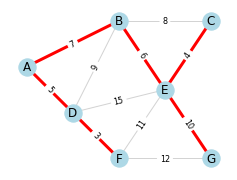

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
pos = {'A': (0, 2), 'B': (2, 3), 'C': (4, 3), 'D': (1, 1), 'E': (3, 1.5), 'F': (2, 0), 'G': (4, 0)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import networkx as nx

N = nx.Graph()
N.add_weighted_edges_from([('A', 'B', 7), ('A', 'D', 5), ('B', 'C', 8), ('B', 'D', 9), ('B', 'E', 6), ('C', 'E', 4),
                          ('D', 'E', 15), ('D', 'F', 3), ('E', 'F', 11), ('E', 'G', 10), ('F', 'G', 12)])
pos = {'A': (0, 2), 'B': (2, 3), 'C': (4, 3), 'D': (1, 1), 'E': (3, 1.5), 'F': (2, 0), 'G': (4, 0)}
T = nx.minimum_spanning_tree(N)
fig, ax = plt.subplots(figsize=(4, 3))
nx.draw(N, pos, ax=ax, with_labels=True, node_color='lightblue', edge_color='lightgray')
nx.draw_networkx_edges(T, pos, ax=ax, edge_color='red', width=3)
nx.draw_networkx_edge_labels(N, pos, edge_labels=nx.get_edge_attributes(N, 'weight'), ax=ax, font_size=8)
plt.show()
```

</details>

`nx.draw_networkx_edges(G, pos, ax=ax, ...)` zeichnet nur die Kanten eines Graphen. So kann man einen Teil eines Graphen hervorheben. Entsprechend gibt es `nx.draw_networkx_nodes`
und `nx.draw_networkx_labels`.

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

G = nx.path_graph(3)
pos = {0: (0, 0), 1: (1, 0), 2: (2, 0)}
fig, ax = plt.subplots(figsize=(3, 1))
nx.draw_networkx_nodes(G, pos, ax=ax, node_color='orange')
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='gray')
nx.draw_networkx_labels(G, pos, ax=ax)
plt.show()

#### Aufgabe 5.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([(1, 2, 5), (2, 3, 1), (1, 3, 2), (3, 4, 7)])
T = nx.minimum_spanning_tree(G)
print(T.size(weight='weight'), T.number_of_edges(), T.has_edge(1, 2))
```

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([(1, 2, 5), (2, 3, 1), (1, 3, 2), (3, 4, 7)])
T = nx.minimum_spanning_tree(G)
print(T.size(weight='weight'), T.number_of_edges(), T.has_edge(1, 2))

## 6. Gemischte Übungen

#### Mehrere Startpunkte

`nx.multi_source_dijkstra_path_length(G, quellen)` gibt für jeden Knoten die Entfernung zur **nächstgelegenen** der Quellen zurück (ein Dictionary).

In [ ]:
import networkx as nx

G = nx.path_graph(5)
print(nx.multi_source_dijkstra_path_length(G, [0, 4]))

#### Aufgabe 6.1

Ein Rettungswagen steht in einer der Wachen `wachen`. Für jeden Ort im Netz `S` (Gewicht: Minuten) soll die nächste Wache bestimmt werden. Gib für jeden Ort die zuständige Wache und die
Fahrzeit aus. Die Fahrzeit liefert `multi_source_dijkstra_path_length`, die Wache selbst bestimmst du mit `dijkstra_path_length` zu jeder Wache.

**Erwartete Ausgabe:**
```
a W1 4
b W2 5
c W2 2
d W2 9
e W2 9
```

In [ ]:
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('W1', 'a', 4), ('a', 'b', 3), ('b', 'W2', 5), ('a', 'c', 6), ('c', 'W2', 2), ('b', 'd', 4), ('d', 'e', 3), ('W2', 'e', 9)])
wachen = ['W1', 'W2']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

S = nx.Graph()
S.add_weighted_edges_from([('W1', 'a', 4), ('a', 'b', 3), ('b', 'W2', 5), ('a', 'c', 6), ('c', 'W2', 2), ('b', 'd', 4), ('d', 'e', 3), ('W2', 'e', 9)])
wachen = ['W1', 'W2']
zeit = nx.multi_source_dijkstra_path_length(S, wachen)
for ort in S.nodes:
    if ort not in wachen:
        wache = min(wachen, key=lambda w: nx.dijkstra_path_length(S, w, ort))
        print(ort, wache, zeit[ort])
```

</details>

#### Aufgabe 6.2

Ein Paket soll vom Lager `L` zum Kunden `K`. Jede Straße hat eine Länge (`weight`) und eine Maut (`maut`). Gib den kürzesten Weg und den billigsten Weg aus, jeweils mit Länge und Maut.

**Erwartete Ausgabe:**
```
['L', 'B', 'K'] 7 5
['L', 'A', 'K'] 14 0
```

In [ ]:
import networkx as nx

G = nx.Graph()
for u, v, km, maut in [('L', 'A', 5, 0), ('A', 'K', 9, 0), ('L', 'B', 3, 2), ('B', 'K', 4, 3), ('A', 'B', 2, 0), ('B', 'C', 6, 0), ('C', 'K', 5, 0)]:
    G.add_edge(u, v, weight=km, maut=maut)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

G = nx.Graph()
for u, v, km, maut in [('L', 'A', 5, 0), ('A', 'K', 9, 0), ('L', 'B', 3, 2), ('B', 'K', 4, 3), ('A', 'B', 2, 0), ('B', 'C', 6, 0), ('C', 'K', 5, 0)]:
    G.add_edge(u, v, weight=km, maut=maut)
for gewicht in ['weight', 'maut']:
    weg = nx.dijkstra_path(G, 'L', 'K', weight=gewicht)
    print(weg, nx.path_weight(G, weg, weight='weight'), nx.path_weight(G, weg, weight='maut'))
```

</details>

#### Aufgabe 6.3

Schreibe eine Funktion `route(G, stationen)`, die für eine Liste von Stationen die kürzesten Teilwege aneinanderhängt und Weg und Gesamtlänge zurückgibt. Gib die Route
Freiburg → Konstanz → Ulm → Heilbronn aus.

**Erwartete Ausgabe:**
```
(['Freiburg', 'Konstanz', 'Ulm', 'Stuttgart', 'Heilbronn'], 430)
```

In [ ]:
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import networkx as nx

BW = nx.Graph()
BW.add_weighted_edges_from([
    ('Stuttgart', 'Karlsruhe', 80), ('Stuttgart', 'Heilbronn', 55), ('Stuttgart', 'Ulm', 95), ('Stuttgart', 'Tübingen', 45),
    ('Stuttgart', 'Pforzheim', 50), ('Karlsruhe', 'Pforzheim', 35), ('Karlsruhe', 'Mannheim', 70), ('Karlsruhe', 'Baden-Baden', 40),
    ('Baden-Baden', 'Freiburg', 105), ('Heilbronn', 'Mannheim', 85), ('Tübingen', 'Konstanz', 150), ('Ulm', 'Konstanz', 145),
    ('Freiburg', 'Konstanz', 135), ('Ulm', 'Tübingen', 110)])
def route(G, stationen):
    weg = [stationen[0]]
    laenge = 0
    for i in range(len(stationen) - 1):
        teil = nx.dijkstra_path(G, stationen[i], stationen[i + 1])
        weg += teil[1:]
        laenge += nx.dijkstra_path_length(G, stationen[i], stationen[i + 1])
    return weg, laenge

print(route(BW, ['Freiburg', 'Konstanz', 'Ulm', 'Heilbronn']))
```

</details>

#### Aufgabe 6.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 2), ('b', 'c', 2), ('c', 'd', 2), ('a', 'd', 5)])
print(nx.dijkstra_path(G, 'a', 'd'), nx.shortest_path(G, 'a', 'd'))
T = nx.minimum_spanning_tree(G)
print(T.has_edge('a', 'd'), T.size(weight='weight'))
```

In [ ]:
import networkx as nx

G = nx.Graph()
G.add_weighted_edges_from([('a', 'b', 2), ('b', 'c', 2), ('c', 'd', 2), ('a', 'd', 5)])
print(nx.dijkstra_path(G, 'a', 'd'), nx.shortest_path(G, 'a', 'd'))
T = nx.minimum_spanning_tree(G)
print(T.has_edge('a', 'd'), T.size(weight='weight'))